# The kriging decoder and global kriging

Global kriging predicts from all the data at once, which means solving a system as large as the
data. In practice one crops the data to a neighbourhood of each target instead. An
ensemble with the kriging decoder takes a third road, kriging inside small random cells and averaging
over many partitions. Here we compare the three on fields whose covariance we know, first where the
theory says the ensemble recovers global kriging, then where it does not.

## What you will learn

- Why an average of local krigings differs from global kriging in general, and when it does not.
- How close the kriging decoder comes to global kriging on a line, the Markov case, and in the plane.
- What cropped kriging is, and how the ensemble compares with it, in accuracy and in seams.
- How the Pareto search chooses the variogram the decoder receives, and what it can and cannot tell.
- How the cost of each grows with the number of data.

*Can an ensemble of local krigings stand in for global kriging?*

## The idea

Global simple kriging projects the value at a location onto the span of all the data, which needs
the $N \times N$ covariance matrix of the data and a cost of order $N^3$. The ensemble projects onto the
data of the location's cell in each partition and averages the results. An average of projections onto
several subspaces is not the projection onto their union, so in general the two differ.

They agree when the field *screens*, that is, when a few nearby data already carry everything the
distant ones would add. The sharp form of screening is the Markov property, under which the value at $x$
depends on the data outside a small set $B(x)$, its *blanket*, only through the data inside it. The book behind
Spatialize proves, in its chapter on the two readings of classical geostatistics, that when the cell
of $x$ contains the blanket, simple kriging from the cell's data equals simple kriging from all the
data, exactly, so the ensemble converges to global kriging at a cost of order $T b^3$, with $b$ the
size of the blanket, instead of $N^3$. A field with an exponential covariance on a line is Markov, its
blanket being the two data on either side of $x$.

Two things keep Spatialize's decoder a little away from that exact statement. Its kriging is
*ordinary* kriging, which estimates the mean from the cell's data instead of taking it as known, and
in some partitions a cut falls between $x$ and one of its blanket data. Outside the Markov case the
local predictor approximates the global one with a residual whose size no theorem bounds. The same
question stands for kriging cropped to a search neighbourhood, so it is open for both methods alike.

## Step by step

### On a line, the Markov case

The field has an exponential covariance with scale 5 on [0, 100], with 200 data at random positions.
We compute global simple kriging directly. The ensemble uses the kriging decoder with the same
covariance. Spatialize's exponential model uses the *practical* range, three times the scale, so the
range is 15.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_griddata, esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf
from spatialize.gs.partitions import cell_labels

spatialize.session.set(empty_cells="coarsen", progress=False)

rng = np.random.default_rng(3)
n, scale, length = 200, 5.0, 100.0
x = np.sort(rng.uniform(0, length, n))
q = np.linspace(0.5, length - 0.5, 1000)
both = np.concatenate([x, q])
cov = np.exp(-np.abs(both[:, None] - both[None, :]) / scale)
field = np.linalg.cholesky(cov + 1e-9 * np.eye(len(both))) @ rng.standard_normal(len(both))
z, truth = field[:n], field[n:]
global_sk = cov[:n, n:].T @ np.linalg.solve(cov[:n, :n], z)
variogram = dict(model="exponential", nugget=0.0, range=3 * scale, sill=1.0)

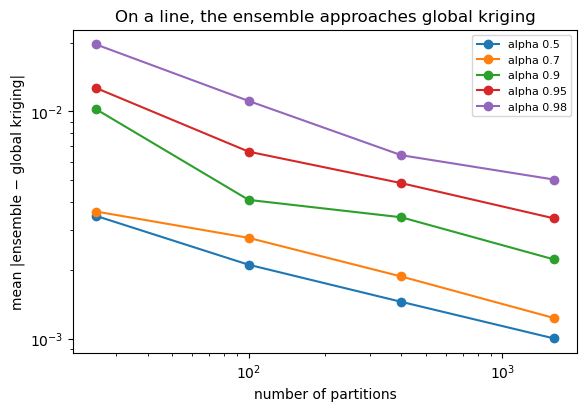

,T = 25,T = 100,T = 400,T = 1600
alpha,,,,
0.50,0.0035,0.0021,0.0015,0.0010
0.70,0.0036,0.0028,0.0019,0.0012
0.90,0.0102,0.0041,0.0034,0.0022
0.95,0.0126,0.0066,0.0048,0.0034
0.98,0.0196,0.0111,0.0064,0.0050


In [2]:
alphas = (0.5, 0.7, 0.9, 0.95, 0.98)
sizes = (25, 100, 400, 1600)
rows = {}
for alpha in alphas:
    rows[alpha] = {}
    for n_partitions in sizes:
        ens = esi_nongriddata(x[:, None], z, q[:, None], local_interpolator="kriging", n_partitions=n_partitions,
                              alpha=alpha, seed=0, **variogram).estimation()
        rows[alpha][n_partitions] = np.mean(np.abs(ens - global_sk))
table = pd.DataFrame(rows).T
table.index.name = "alpha"

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for alpha in alphas:
    ax.plot(sizes, table.loc[alpha], "o-", label=f"alpha {alpha}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("number of partitions"); ax.set_ylabel("mean |ensemble − global kriging|")
ax.set_title("On a line, the ensemble approaches global kriging")
ax.legend(fontsize=8)
plt.show()
table.rename(columns=lambda t: f"T = {t}").round(4)

The figure and the table give the mean absolute difference between the ensemble and global kriging, for a field of
standard deviation 1. It lies between a thousandth and two hundredths, falling more and more slowly
as the partitions multiply, and smallest for coarse partitions. The level it reaches is set by
the share of partitions whose cell around $x$ keeps the blanket.

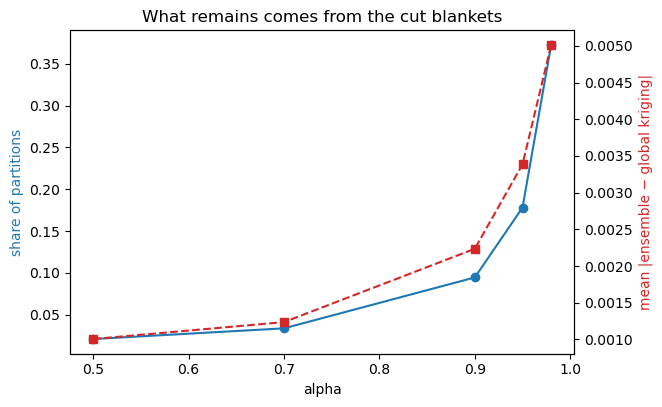

,partitions keeping the blanket in the cell
0.50,0.979
0.70,0.966
0.90,0.905
0.95,0.822
0.98,0.628


In [3]:
left = np.searchsorted(x, q) - 1
inside = (left >= 0) & (left < n - 1)
where = np.concatenate([q[inside], x[left[inside]], x[left[inside] + 1]])[:, None]
k = inside.sum()
kept_share = {}
for alpha in alphas:
    labels = cell_labels(x[:, None], where, alpha=alpha, n_partitions=400, seed=0)
    kept = (labels[:k] == labels[k:2 * k]) & (labels[:k] == labels[2 * k:])
    kept_share[alpha] = kept.mean()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(alphas, [1 - kept_share[a] for a in alphas], "o-", color="C0", label="partitions cutting the blanket")
ax.set_xlabel("alpha"); ax.set_ylabel("share of partitions", color="C0")
twin = ax.twinx()
twin.plot(alphas, table[1600], "s--", color="C3", label="difference at T = 1600")
twin.set_ylabel("mean |ensemble − global kriging|", color="C3")
ax.set_title("What remains comes from the cut blankets")
plt.show()
pd.DataFrame({"partitions keeping the blanket in the cell": kept_share}).round(3)

With coarse partitions almost every cell around a location holds both of its neighbours, so almost
every member is global kriging, up to the mean the cell estimates. As the cells shrink, more partitions
cut the blanket, whose members leave a residual that more partitions average but do not remove. The
two curves of the figure rise together, the difference at 1 600 partitions following the share of
partitions that cut the blanket.

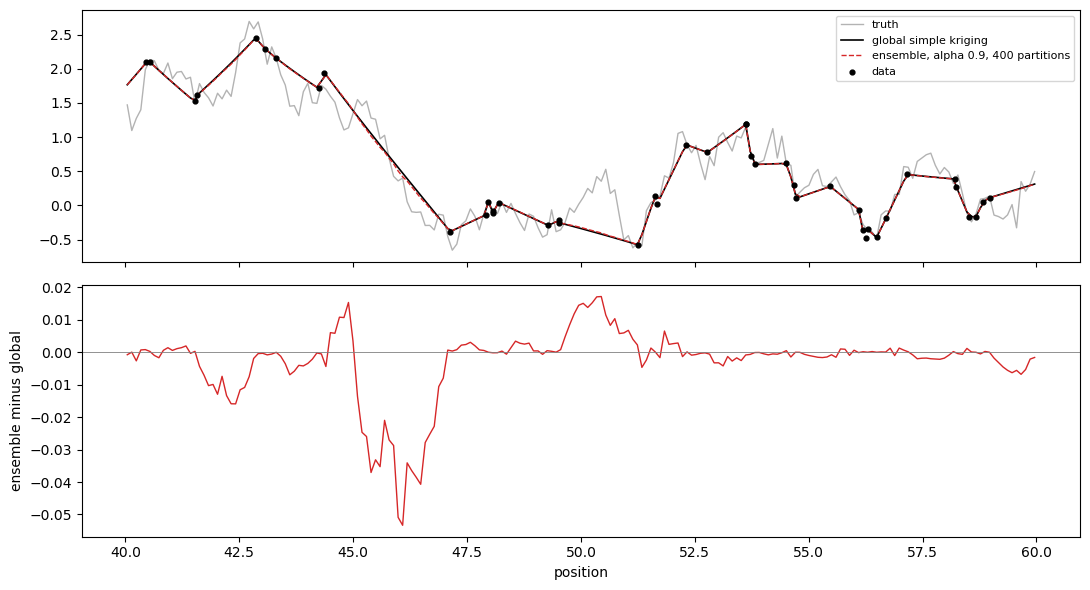

In [4]:
ens = esi_nongriddata(x[:, None], z, q[:, None], local_interpolator="kriging", n_partitions=400, alpha=0.9,
                      seed=0, **variogram).estimation()
zoom = (q > 40) & (q < 60)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(q[zoom], truth[zoom], color="0.7", lw=1, label="truth")
axes[0].plot(q[zoom], global_sk[zoom], color="black", lw=1.2, label="global simple kriging")
axes[0].plot(q[zoom], ens[zoom], color="C3", lw=1, ls="--", label="ensemble, alpha 0.9, 400 partitions")
in_zoom = (x > 40) & (x < 60)
axes[0].scatter(x[in_zoom], z[in_zoom], color="black", s=12, zorder=3, label="data")
axes[0].legend(fontsize=8)
axes[1].plot(q[zoom], ens[zoom] - global_sk[zoom], color="C3", lw=1)
axes[1].axhline(0, color="0.5", lw=0.6)
axes[1].set_ylabel("ensemble minus global")
axes[1].set_xlabel("position")
plt.tight_layout()
plt.show()

The two curves lie on top of each other at this scale, while the difference in the lower panel stays
within a few hundredths, larger where the data are sparse.

### In the plane, outside the Markov case

An isotropic field with an exponential covariance of scale 8 in the plane is not Markov, so no finite
blanket screens a location exactly. We compare three predictions on a 64 × 64 grid from 400 data at
random positions, namely global simple kriging, cropped kriging, and the ensemble.

*Cropped kriging*, kriging in a *search neighbourhood*, is the usual way to keep kriging affordable with
many data. For each target it keeps only the $k$ data nearest to it, ignoring the rest, then solves the
$k \times k$ kriging system of those. Every target has its own small system, so the cost grows with the
number of targets instead of the cube of the data. Two nearby targets share most of their nearest data.
The system changes at once as a target moves past the point at which one datum leaves its $k$ nearest
and another enters, so the prediction jumps there. Software for kriging commonly crops to some 8 to
32 data. We crop to 4, which makes the jumps easy to see.

In [5]:
m, scale2 = 64, 8.0
nodes = np.stack(np.meshgrid(np.arange(m) + 0.5, np.arange(m) + 0.5, indexing="ij"), -1).reshape(-1, 2)
cov2 = lambda a, b: np.exp(-np.sqrt(((a[:, None, :] - b[None, :, :]) ** 2).sum(-1)) / scale2)
rng = np.random.default_rng(4)
p = rng.uniform(0, m, (400, 2))
together = np.vstack([p, nodes])
field2 = np.linalg.cholesky(cov2(together, together) + 1e-8 * np.eye(len(together))) @ rng.standard_normal(len(together))
v, truth2 = field2[:400], field2[400:].reshape(m, m)

global2 = (cov2(nodes, p) @ np.linalg.solve(cov2(p, p), v)).reshape(m, m)
_, nearest = cKDTree(p).query(nodes, k=4)
cropped = np.array([cov2(nodes[i:i + 1], p[nearest[i]])[0] @ np.linalg.solve(cov2(p[nearest[i]], p[nearest[i]]), v[nearest[i]])
                    for i in range(len(nodes))]).reshape(m, m)
xi = np.stack(np.meshgrid(np.arange(m) + 0.5, np.arange(m) + 0.5, indexing="ij"))
ensemble2 = esi_griddata(p, v, xi, local_interpolator="kriging", n_partitions=400, alpha=0.8, seed=0,
                         model="exponential", nugget=0.0, range=3 * scale2, sill=1.0).estimation()

def roughness(f):
    return np.abs(np.diff(f, axis=0)).mean()

pd.DataFrame({name: {"difference from global kriging": round(np.mean(np.abs(f - global2)), 4),
                     "roughness against global kriging": round(roughness(f) / roughness(global2), 2),
                     "true MAE": round(np.mean(np.abs(f - truth2)), 3)}
              for name, f in (("global kriging", global2), ("cropped to 4 neighbours", cropped),
                              ("ensemble, alpha 0.8", ensemble2))}).T

,difference from global kriging,roughness against global kriging,true MAE
global kriging,0.0000,1.00,0.367
cropped to 4 neighbours,0.0821,1.13,0.379
"ensemble, alpha 0.8",0.0207,0.98,0.368


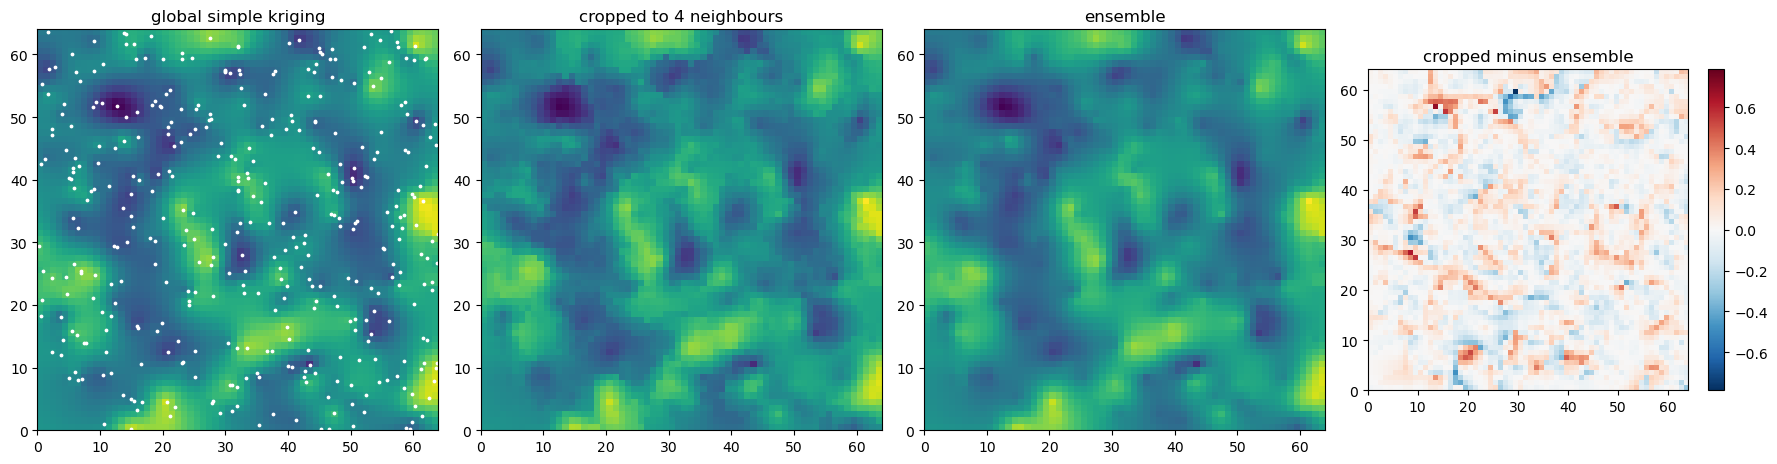

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
lim = np.abs(cropped - ensemble2).max()
for ax, (title, f, cmap, bounds) in zip(axes, [
        ("global simple kriging", global2, "viridis", (global2.min(), global2.max())),
        ("cropped to 4 neighbours", cropped, "viridis", (global2.min(), global2.max())),
        ("ensemble", ensemble2, "viridis", (global2.min(), global2.max())),
        ("cropped minus ensemble", cropped - ensemble2, "RdBu_r", (-lim, lim))]):
    im = ax.imshow(f.T, origin="lower", extent=(0, m, 0, m), cmap=cmap, vmin=bounds[0], vmax=bounds[1])
    ax.set_title(title)
axes[0].scatter(p[:, 0], p[:, 1], s=3, c="white")
fig.colorbar(im, ax=axes[3], shrink=0.8)
plt.tight_layout()
plt.show()

A row of the grid shows the three predictions side by side. The crop leaves global kriging in a few
places, near x = 9, 37 and 55, where the four nearest data lie off to one side, while the ensemble
stays close to it all along.

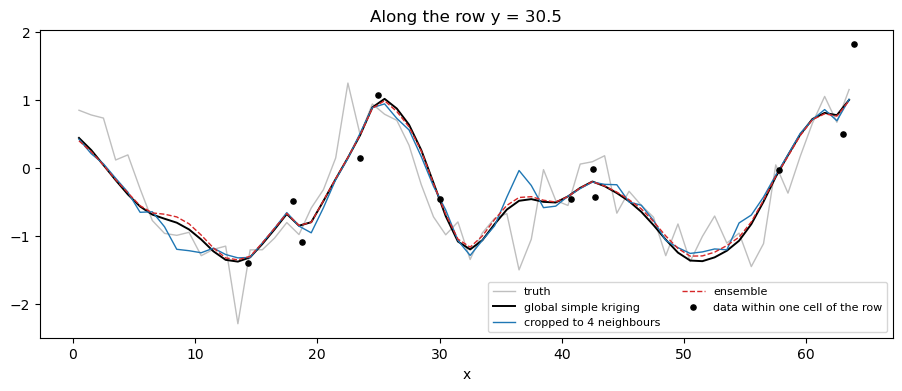

In [7]:
row = 30
fig, ax = plt.subplots(figsize=(11, 4))
cols = np.arange(m) + 0.5
ax.plot(cols, truth2[:, row], color="0.75", lw=1, label="truth")
ax.plot(cols, global2[:, row], color="black", lw=1.4, label="global simple kriging")
ax.plot(cols, cropped[:, row], color="C0", lw=1, label="cropped to 4 neighbours")
ax.plot(cols, ensemble2[:, row], color="C3", lw=1, ls="--", label="ensemble")
near_row = np.abs(p[:, 1] - (row + 0.5)) < 1
ax.scatter(p[near_row, 0], v[near_row], color="black", s=14, zorder=3, label="data within one cell of the row")
ax.set_xlabel("x"); ax.set_title(f"Along the row y = {row + 0.5}")
ax.legend(fontsize=8, ncol=2)
plt.show()

The cropped prediction differs from global kriging about four times more than the ensemble does, while
being rougher, with seams where the set of four neighbours changes as the target moves, visible in the
difference panel as straight edges. The ensemble reads a different neighbourhood in every partition,
so no single change of membership survives the average, which leaves its map about as smooth as global
kriging's. Neither reproduces global kriging exactly, since in the plane neither the cell nor the
crop screens the distant data completely.

### Inferring the variogram with the Pareto search

So far the decoder received the true covariance. In practice the variogram is unknown. The usual
route fits a model to the experimental variogram of the data. Here we let the Pareto search choose it,
the model, the range and the nugget entering as hyperparameters of the decoder next to `alpha`. Each
candidate is scored by the leave-one-out error of its ensemble. The encoder error $\hat\varepsilon$
reads only the cells of the partitions, so it moves with `alpha` alone, while the variogram moves the
decoder error. We score by the mean absolute error. The default score, the likelihood of the members,
rewards members that disagree, while kriging members with a fitting variogram agree closely. The
search takes a few minutes.

knee at alpha 0.8, exponential model, range 40.0, nugget 0.0


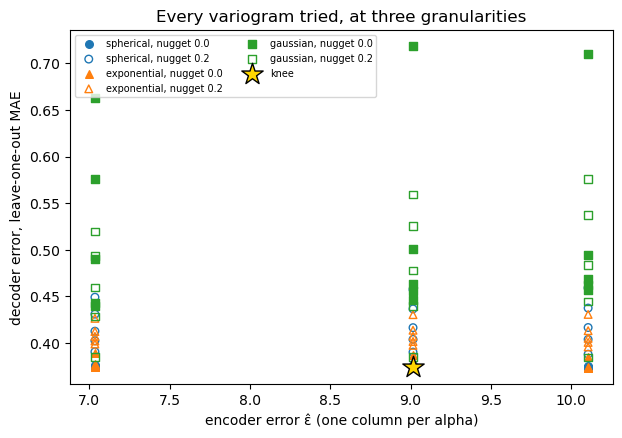

In [8]:
models, ranges = ["spherical", "exponential", "gaussian"], [8.0, 16.0, 24.0, 40.0, 64.0]
search = esi_pareto_hparams_search(p, v, local_interpolator="kriging", n_partitions=[100], alpha=[0.7, 0.8, 0.9],
                                   model=models, range=ranges, nugget=[0.0, 0.2], sill=[1.0],
                                   k="loo", scoring=sf.mae, seed=0)
runs = pd.DataFrame([{**{key: r["params"][key] for key in ("alpha", "model", "range", "nugget")},
                      "encoder ε̂": r["epsilon"], "decoder error": r["decoder_error"]} for r in search.all_results])
knee = search.best_result(strategy="knee")
print(f"knee at alpha {knee['alpha']}, {knee['model']} model, range {knee['range']}, nugget {knee['nugget']}")

fig, ax = plt.subplots(figsize=(7, 4.6))
for model, marker in zip(models, "o^s"):
    for nugget, fill in ((0.0, True), (0.2, False)):
        part = runs[(runs.model == model) & (runs.nugget == nugget)]
        ax.scatter(part["encoder ε̂"], part["decoder error"], marker=marker, s=30,
                   color=f"C{models.index(model)}" if fill else "none", edgecolors=f"C{models.index(model)}",
                   label=f"{model}, nugget {nugget}")
ax.scatter(knee["epsilon"], knee["decoder_error"], marker="*", s=260, color="gold", edgecolors="black", zorder=3,
           label="knee")
ax.set_xlabel("encoder error ε̂ (one column per alpha)"); ax.set_ylabel("decoder error, leave-one-out MAE")
ax.set_title("Every variogram tried, at three granularities")
ax.legend(fontsize=7, ncol=2)
plt.show()

Each column of points is one value of `alpha`, finer to the left. Within a column the variograms
spread the decoder error widely. The Gaussian model sits at the top of every column. The nugget raises
the error of the exponential and spherical models, so the knee picks a model without nugget, as the
truth has none.

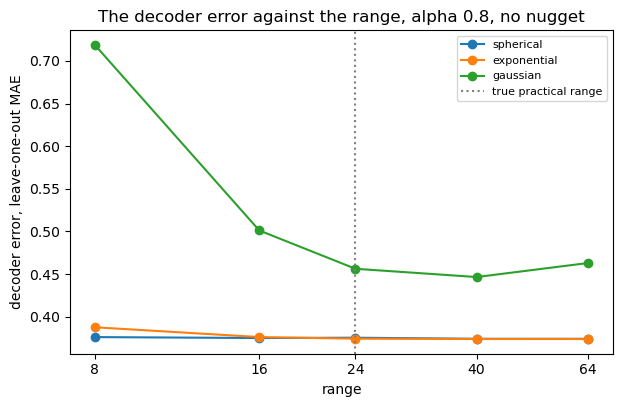

,true MAE
"true variogram, alpha 0.8",0.368
variogram at the knee,0.367
"Gaussian, range 64, nugget 0.2",0.544


In [9]:
at_knee = runs[(runs.alpha == knee["alpha"]) & (runs.nugget == 0.0)]
fig, ax = plt.subplots(figsize=(7, 4.2))
for model in models:
    part = at_knee[at_knee.model == model].sort_values("range")
    ax.plot(part["range"], part["decoder error"], "o-", label=model)
ax.axvline(3 * scale2, color="0.5", ls=":", label="true practical range")
ax.set_xscale("log"); ax.set_xticks(ranges, [f"{r:g}" for r in ranges]); ax.minorticks_off()
ax.set_xlabel("range"); ax.set_ylabel("decoder error, leave-one-out MAE")
ax.set_title(f"The decoder error against the range, alpha {knee['alpha']}, no nugget")
ax.legend(fontsize=8)
plt.show()

chosen = esi_griddata(p, v, xi, local_interpolator="kriging", n_partitions=400, alpha=knee["alpha"], seed=0,
                      model=knee["model"], nugget=knee["nugget"], range=knee["range"], sill=1.0).estimation()
poor = esi_griddata(p, v, xi, local_interpolator="kriging", n_partitions=400, alpha=knee["alpha"], seed=0,
                    model="gaussian", nugget=0.2, range=64.0, sill=1.0).estimation()
pd.DataFrame({"true MAE": {"true variogram, alpha 0.8": np.mean(np.abs(ensemble2 - truth2)),
                           "variogram at the knee": np.mean(np.abs(chosen - truth2)),
                           "Gaussian, range 64, nugget 0.2": np.mean(np.abs(poor - truth2))}}).round(3)

The exponential and spherical curves are almost flat over a wide band of ranges around the true one,
while the Gaussian one lies well above them. The leave-one-out error pins down the nugget and the
shape of the variogram near the origin better than the range. A range the data leave loose also
moves the prediction little, so the map from the variogram at the knee is as close to the truth as the
map from the true variogram, while a poor model loses about half as much again.

The maps show where the variograms differ.

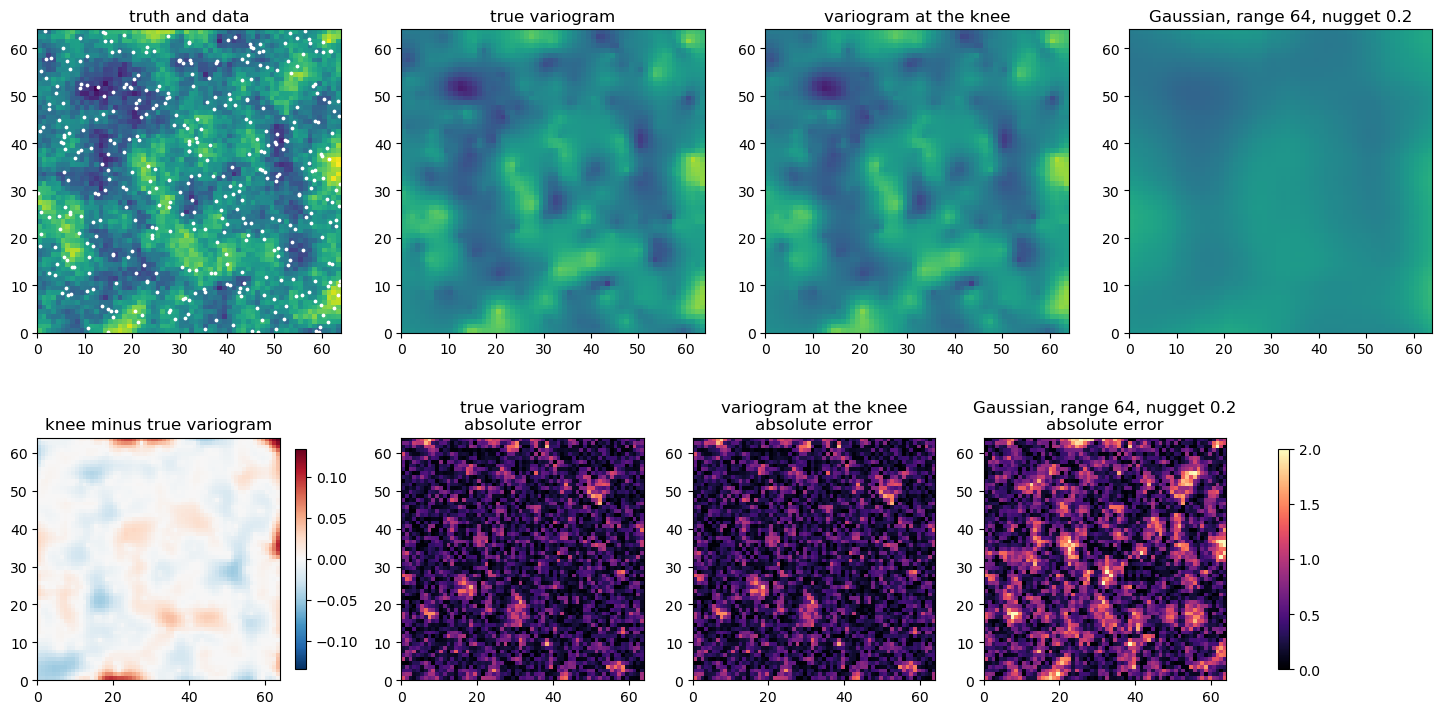

In [10]:
estimates = {"true variogram": ensemble2, "variogram at the knee": chosen, "Gaussian, range 64, nugget 0.2": poor}
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
low, high = truth2.min(), truth2.max()
axes[0, 0].imshow(truth2.T, origin="lower", extent=(0, m, 0, m), cmap="viridis", vmin=low, vmax=high)
axes[0, 0].scatter(p[:, 0], p[:, 1], s=3, c="white")
axes[0, 0].set_title("truth and data")
gap = chosen - ensemble2
lim = np.abs(gap).max()
im = axes[1, 0].imshow(gap.T, origin="lower", extent=(0, m, 0, m), cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1, 0].set_title("knee minus true variogram")
fig.colorbar(im, ax=axes[1, 0], shrink=0.7)
for col, (name, f) in enumerate(estimates.items(), start=1):
    axes[0, col].imshow(f.T, origin="lower", extent=(0, m, 0, m), cmap="viridis", vmin=low, vmax=high)
    axes[0, col].set_title(name)
    err = axes[1, col].imshow(np.abs(f - truth2).T, origin="lower", extent=(0, m, 0, m), cmap="magma", vmin=0, vmax=2)
    axes[1, col].set_title(f"{name}\nabsolute error")
fig.colorbar(err, ax=axes[1, 1:], shrink=0.7)
plt.show()

The maps from the true variogram and from the knee cannot be told apart. Their difference stays within
about a tenth of the field's standard deviation, largest along the edges of the grid, where fewer data
surround a location. The Gaussian model with a nugget smooths the field almost flat, so its error grows
wherever the truth strays far from the mean.

### The cost against the number of data

Global kriging forms and solves the $N \times N$ system. The ensemble solves one small system per cell
and partition. To keep the cells small as the data grow, `alpha` rises with $N$ so that a cell holds
about thirty data.

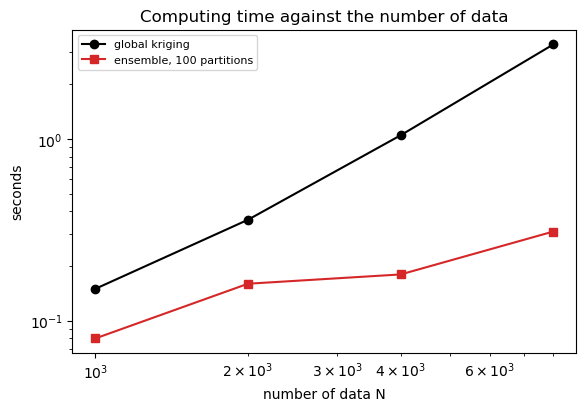

,alpha,"ensemble, 100 partitions (s)",global kriging (s)
1000,0.8953,0.08,0.15
2000,0.9302,0.16,0.36
4000,0.9526,0.18,1.05
8000,0.9674,0.31,3.32


In [11]:
rng = np.random.default_rng(1)
cost = {}
for n_data in (1000, 2000, 4000, 8000):
    pts = rng.uniform(0, m, (n_data, 2))
    vals = rng.standard_normal(n_data)
    alpha = 1 - 0.5 / (np.sqrt(n_data / 30) - 1)
    start = time.perf_counter()
    esi_griddata(pts, vals, xi, local_interpolator="kriging", n_partitions=100, alpha=alpha, seed=0,
                 model="exponential", nugget=0.0, range=3 * scale2, sill=1.0)
    t_ens = time.perf_counter() - start
    start = time.perf_counter()
    np.linalg.solve(cov2(pts, pts), cov2(pts, nodes))
    t_glob = time.perf_counter() - start
    cost[n_data] = {"alpha": round(alpha, 4), "ensemble, 100 partitions (s)": round(t_ens, 2),
                    "global kriging (s)": round(t_glob, 2)}
cost = pd.DataFrame(cost).T

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(cost.index, cost["global kriging (s)"], "o-", color="black", label="global kriging")
ax.plot(cost.index, cost["ensemble, 100 partitions (s)"], "s-", color="C3", label="ensemble, 100 partitions")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("number of data N"); ax.set_ylabel("seconds")
ax.set_title("Computing time against the number of data")
ax.legend(fontsize=8)
plt.show()
cost

Over an eightfold growth of the data the global system's time grows about twentyfold, more steeply
from one doubling to the next, towards the cube of $N$ once the data outnumber the locations to predict.
The ensemble's time grows less than fivefold, since each of its systems stays the size of a cell. Memory follows the same pattern, the global matrix taking
$8N^2$ bytes, half a gigabyte at 8 000 data.

## What can go wrong

- **Expecting equality outside the Markov case.** In the plane the ensemble approximates global kriging
  without matching it, and so does every search neighbourhood. Measure the difference on your own
  covariance before relying on it.
- **A wrong variogram.** The ensemble inherits it in every cell, as global kriging would. Spatialize's
  exponential model takes the practical range, three times the scale of the covariance.
- **Cells too fine.** With few data per cell, more partitions cut the blanket, while each local system is
poorly conditioned. Keep a few tens of data per cell, the granularity the Pareto search tends to find.
- **A likelihood score for the variogram.** The search scores by the likelihood of the members by
  default, which suits ensembles whose members spread. Kriging members with a well-chosen variogram
  agree so closely that the density fitted to them is very narrow, so the likelihood prefers the
  variogram whose members disagree most, here the Gaussian one, the worst by the error. Score a
  variogram by an error of the prediction, such as `sf.mae`.
- **Reading the range off the search.** The decoder error barely changes over a wide band of ranges,
  so the range at the knee is one of many the data allow. Treat it as a setting of the predictor,
  not as a measurement of the field.
- **Ordinary and simple kriging.** The decoder estimates the mean in every cell, while the theory's
  exact statement is for a known mean. On a field whose mean drifts, that local estimate is a benefit.

## Try it yourself

1. Change `scale` on the line to 2 and to 20, and see how the difference from global kriging moves.
2. Crop to 8 or 16 neighbours instead of 4 and compare the seams and the difference with the ensemble.
3. Use the spherical model, both in the field and in the decoder, and repeat the comparison in the
   plane.
4. Add a measurement error to the data in the plane, `v + rng.normal(0, 0.4, 400)`, and see whether the
   variogram search moves to the nugget 0.2.

## Next

- *Classical interpolators*, for the ensemble against kriging and other methods on real data.
- *The variogram as an inference*, for estimating the covariance the kriging decoder needs.
- *The decoders*, for the other local interpolators.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) (theory).